# 02 - Keyword Cleaning & EDA

Loads `raw_articles.pkl` and applies keyword cleaning.
All optional steps can be turned on/off independently.

In [1]:
import pandas as pd
import re
import unicodedata
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from wordcloud import WordCloud

CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / 'big_data').exists() else CWD.parent
BIG_DATA = PROJECT_ROOT / 'big_data'
DATA_DIR = PROJECT_ROOT / 'data'

PICKLE_IN  = BIG_DATA / 'baseline' / 'pickle' / 'raw_articles.pkl'
PICKLE_OUT = BIG_DATA / 'baseline' / 'pickle' / 'clean_articles.pkl'

df_raw = pd.read_pickle(PICKLE_IN)
print(f"Loaded: {df_raw.shape[0]} articles, {df_raw.shape[1]} columns")
df_raw.head(2)

Loaded: 41449 articles, 16 columns


,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,methods,results,discussion,conclusion,tables,metadata_junk
0,PMC3000446.xml,PMC3000446,10.1136/bjo.2010.182402,Br J Ophthalmol The British Journal of Ophthal...,2010,Crosby Michelle B; Yang Hua; Gao Weiqing; Zhan...,Serum vascular endothelial growth factor (VEGF...,Pathology; neoplasia,A preliminary animal study was performed to de...,Uveal melanoma is the most common primary mali...,"B16LS9 cells (courtesy of D. Rusciano, Friedri...",Serum VEGF levels rose after inoculation of C5...,We have shown that serum VEGF levels rise over...,,,
1,PMC3000522.xml,PMC3000522,10.1016/j.plefa.2010.07.006,Prostaglandins Leukot Essent Fatty Acids Prost...,2010,Slater-Jefferies Joanne L.; Hoile Samuel P.; L...,Effect of sex and dietary fat intake on the fa...,Fatty acids; Heart; Phophospholipids; Rat; Sex...,Variations in the fatty acid composition of li...,The fatty acid composition of membranes is an ...,Diets were from Special Diets Services (Witham...,Analysis of the fatty acid compositions of ind...,The findings of this study show that feeding d...,,Pregnancy Lactation Post-weaning diet Diets Di...,


In [2]:
# =============================================================================
# POST-PICKLE ARTEFACT CLEANING
# =============================================================================

# 1. AUTHOR ARTEFACTS
# data_extraction.py used str(xpath_list) which produced "['Smith'] ['John']" repr.
# Fixed at source in v3 — but existing pickles still need post-processing.
df_raw['authors'] = df_raw['authors'].str.replace(r"\['|'\]", "", regex=True)

# 2. MOJIBAKE (encoding artefacts)
# These appear because some XML content was re-encoded from UTF-8 → latin-1 and back.
# Common patterns found in xml_attr_frequencies.csv:
#   â€"  → –  (U+2013 en-dash,  UTF-8: 0xE2 0x80 0x93 misread as latin-1)
#   â€"  → —  (U+2014 em-dash,  UTF-8: 0xE2 0x80 0x94)
#   Â±   → ±  (U+00B1 plus-minus, UTF-8: 0xC2 0xB1 misread as latin-1)
#   Â·   → ·  (U+00B7 middle dot)
#   â‰¤  → ≤  (U+2264 less-than-or-equal)
#   â€˜  → '  (U+2018 left single quote)
#   â€™  → '  (U+2019 right single quote)

MOJIBAKE = {
    'â€"':  '–',
    'â€"':  '—',
    'Â±':   '±',
    'Â·':   '·',
    'â‰¤':  '≤',
    'â‰¥':  '≥',
    'â€˜':  '‘',
    'â€™':  '’',
    'â€œ':  '"',
    'â€': '"',
    'Ã©':   'é',
    'Ã¼':   'ü',
    'Ã¶':   'ö',
    'Ã¤':   'ä',
    'Ã': 'ß',
    'Â ': ' ',   # non-breaking space
}

def fix_mojibake(text: str) -> str:
    if not isinstance(text, str):
        return text
    for bad, good in MOJIBAKE.items():
        text = text.replace(bad, good)
    return text

# Apply to all text columns
TEXT_COLS = ['title', 'abstract', 'introduction', 'methods',
             'results', 'discussion', 'conclusion', 'keywords', 'authors']

for col in TEXT_COLS:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].apply(fix_mojibake)

print("Artefact cleaning done.")
df_raw.iloc[1000:1004, 0:8].T


Artefact cleaning done.


,1000,1001,1002,1003
filename,PMC3021324.xml,PMC3021332.xml,PMC3021315.xml,PMC3021333.xml
pmcid,PMC3021324,PMC3021332,PMC3021315,PMC3021333
doi,,,10.4293/108680810X12674612014707,
journal,JSLS JSLS : Journal of the Society of Laparoen...,JSLS JSLS : Journal of the Society of Laparoen...,JSLS JSLS : Journal of the Society of Laparoen...,JSLS JSLS : Journal of the Society of Laparoen...
year,2000,2003,2010,2003
authors,Jacobs Volker R.; Morrison John E.; Mundhenke ...,Fernando Hiran C.; Schauer Philip R.; Buenaven...,Fanning James; Hojat Rod; Johnson Jil; Fenton ...,Cohen Shlomo B.; Wattiez Arnaud; Seidman Danie...
title,Intraoperative Evaluation of Laparoscopic Insu...,Outcomes of Minimally Invasive Antireflux Oper...,Laparoscopic Cytoreduction for Primary Advance...,Laparoscopy Versus Laparotomy for Detorsion an...
keywords,Data acquisition; Insufflation technique; Lapa...,Antireflux operation; Elderly; Gastroesophagea...,Cytoreduction; Omentectomy; Ovarian cancer; Sa...,Laparoscopy; Laparotomy; Ovarian torsion; Twis...


## 1 - clean_text helper

In [3]:
def clean_text(text: str) -> str:
    """
    Normalise text for NLP:
    1. Unicode NFKD normalisation: decomposes characters (é → e + combining accent)
    2. ASCII encoding: drops non-ASCII (accents, special chars) — safe after mojibake fix
    3. Decimal point protection: preserves numbers like 3.14 through the cleaning
    4. Remove remaining non-alphanumeric characters (except decimal points)
    5. Normalise whitespace

    Note: mojibake artefacts (â€", Â±, etc.) are fixed BEFORE this step
    in the post-pickle cleaning cell above, so they are correctly converted
    rather than silently dropped here.
    """
    if not isinstance(text, str) or not text:
        return ""
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'(\d)\.(\d)', r'\1T1E2M3P4\2', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = text.replace('T1E2M3P4', '.')
    text = re.sub(r'\s+', ' ', text).strip()
    return text

## 2 - Keyword Cleaning

**first: simple** 

blacklist only - no subj-group splitting yet.
Enable splitting later if baseline F1 is poor.

In [ ]:
#remove abbreviations in front of the actual keyword, e.g. "_cns_ central nervous system"
# After pd.read_pickle():
import re

abbrevs = {}  # abbrev → full name
clean_kws = []
i=0
for kw in df_raw['keywords']:
    i+=1
    if re.match(r'^[a-z0-9-]{2,8},\s+[a-z]', kw):
        parts = kw.split(',', 1)
        abbrev = parts[0].strip()
        full = parts[1].strip()
        abbrevs[abbrev] = full  # e.g. "dmem" → "dulbecco's modified eagle's medium"
        if i<50:
            print(f"{kw}: abbrev: {abbrev} - full: {full}")
    else:
        clean_kws.append(kw)
        if i<50:
            print(f"--- is clean: {kw}")
    



# --- Noise filter ---
# noise_words : single tokens -> checked against individual words of a keyword
# noise_phrases: multi-word strings -> checked against the full keyword string
noise_words = {
    'research', 'article', 'articles', 'review', 'reviews',
    'original', 'study', 'paper', 'papers', 'report', 'reports',
    'investigation', 'chemistry', 'clinical', 'full',
    'dentistry', 'science',
}
noise_phrases = {
    'biological sciences', 'case report', 'original research',
    'original article', 'original investigation',
    'methods online', 'scientific papers', 'clinical science'
}

df = df_raw.copy()

def filter_keywords(kwd_str: str) -> list:
    if not isinstance(kwd_str, str):
        return []
    result = []
    for k in kwd_str.split(';'):
        k = k.strip()
        if not k:
            continue
        k_lower = k.lower()
        k_words = set(k_lower.split())
        if k_lower not in noise_phrases and not any(n in k_words for n in noise_words):
            result.append(k)
    return result

df['kwd_lst']    = df['keywords'].apply(filter_keywords)
df['kwd_lst_cl'] = df['kwd_lst'].apply(lambda kwds: [clean_text(k).lower() for k in kwds])
df['n_keywords'] = df['kwd_lst_cl'].apply(len)

print(f"Articles with >= 1 keyword: {(df['n_keywords'] > 0).sum()}")
df[['keywords', 'kwd_lst', 'n_keywords']].head(3)

Articles with >= 1 keyword: 41336


,keywords,kwd_lst,n_keywords
0,pathology; neoplasia,"[pathology, neoplasia]",2
1,heart; phophospholipids; rat; sex; triacylglyc...,"[heart, phophospholipids, rat, sex, triacylgly...",5
2,"cmf; ffa; v1; contrast gain, face recognition","[cmf, ffa, v1, contrast gain, face recognition]",4


## 3 - Keyword Frequency Filter

Filter by minimum corpus frequency. OCIS-coded keywords excluded. Articles with no remaining valid keywords are dropped.

In [6]:
# Flatten all cleaned keywords
lst_keys = [key for kws in df["kwd_lst_cl"].dropna() for key in kws if key]

keyword_counts = pd.Series(lst_keys).value_counts()

print(f"Total unique      : {len(keyword_counts)}")
print(f"After min_freq=2  : {(keyword_counts >= 2).sum()}")
print(f"After min_freq=10 : {(keyword_counts >= 10).sum()}")
print(f"After min_freq=20 : {(keyword_counts >= 20).sum()}")

Total unique      : 69677
Nach min_freq=2   : 18981
Nach min_freq=10  : 2486
Nach min_freq=20  : 1001


In [7]:
# Tradeoff: keywords retained vs articles lost per threshold
for mf in [5, 10, 20]:
    valid = set(keyword_counts[keyword_counts >= mf].index)
    valid_no_ocis = {k for k in valid if not re.match(r"^\d+\.\d+", k)}
    empty = df["kwd_lst_cl"].apply(
        lambda kws: len([k for k in kws if k in valid_no_ocis]) == 0 if isinstance(kws, list) else True
    ).sum()
    print(f"min_freq={mf:>2}: {len(valid_no_ocis):>5} keywords retained | {100*empty/len(df):.1f}% articles lost")

min_freq= 5:  5703 keywords retained | 12.4% articles lost
min_freq=10:  2464 keywords retained | 20.7% articles lost
min_freq=20:   990 keywords retained | 32.3% articles lost


valid_keywords: 2464
Articles dropped : 8593 (20.7%)
Articles retained: 32856


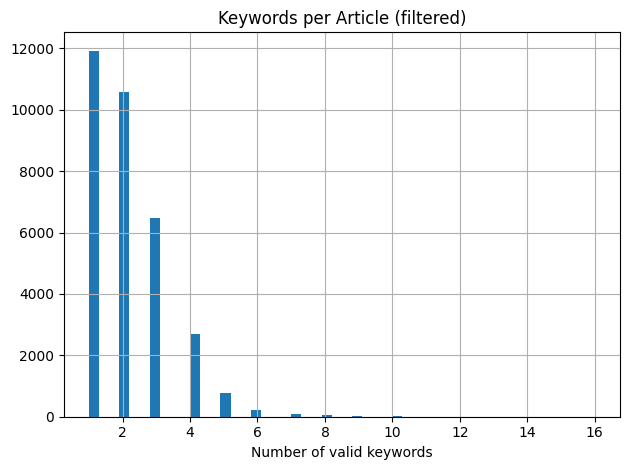

In [8]:
# Keywords with freq < 10 excluded: insufficient training samples per class
# -> class imbalance + overfitting risk
# OCIS-coded keywords (float prefix e.g. "170.6935 ...") excluded: journal-specific
min_freq = 10

valid_keywords = set(keyword_counts[keyword_counts >= min_freq].index)
valid_keywords = {k for k in valid_keywords if not re.match(r"^\d+\.\d+", k)}
print(f"valid_keywords: {len(valid_keywords)}")

df["keywords_filtered"] = df["kwd_lst_cl"].apply(
    lambda kws: [k for k in kws if k in valid_keywords] if isinstance(kws, list) else []
)

n_before = len(df)
df = df[df["keywords_filtered"].apply(len) > 0].copy()
print(f"Articles dropped : {n_before - len(df)} ({100*(n_before-len(df))/n_before:.1f}%)")
print(f"Articles retained: {len(df)}")

df["keywords_filtered"].apply(len).hist(bins=50)
plt.title("Keywords per Article (filtered)")
plt.xlabel("Number of valid keywords")
plt.tight_layout()
plt.show()

## 4 - EDA Plots

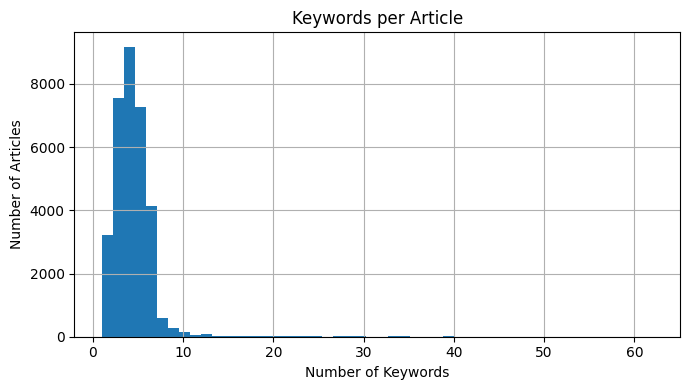

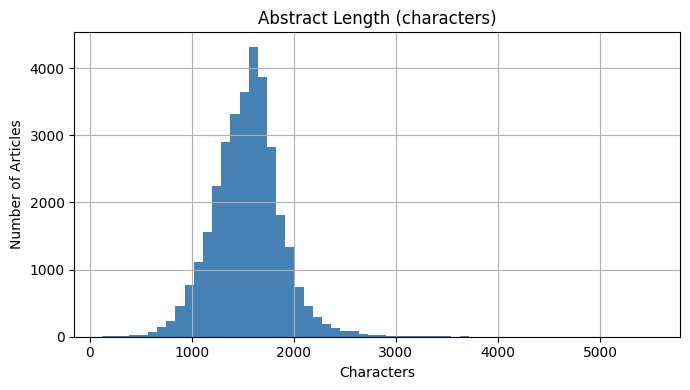

In [15]:
# Plot 1: Keywords per article
fig1, ax1 = plt.subplots(figsize=(7, 4))
df['n_keywords'].hist(bins=50, ax=ax1)
ax1.set_title('Keywords per Article')
ax1.set_xlabel('Number of Keywords')
ax1.set_ylabel('Number of Articles')
plt.tight_layout()
plt.savefig("keyword_hist.png", dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Abstract length
fig2, ax2 = plt.subplots(figsize=(7, 4))
df['abstract'].apply(len).hist(bins=60, ax=ax2, color='steelblue')
ax2.set_title('Abstract Length (characters)')
ax2.set_xlabel('Characters')
ax2.set_ylabel('Number of Articles')
plt.tight_layout()
plt.savefig("abstract_length_hist.png", dpi=150, bbox_inches='tight')
plt.show()

df[df['n_keywords'] > 20]['keywords'].to_csv('test.csv')

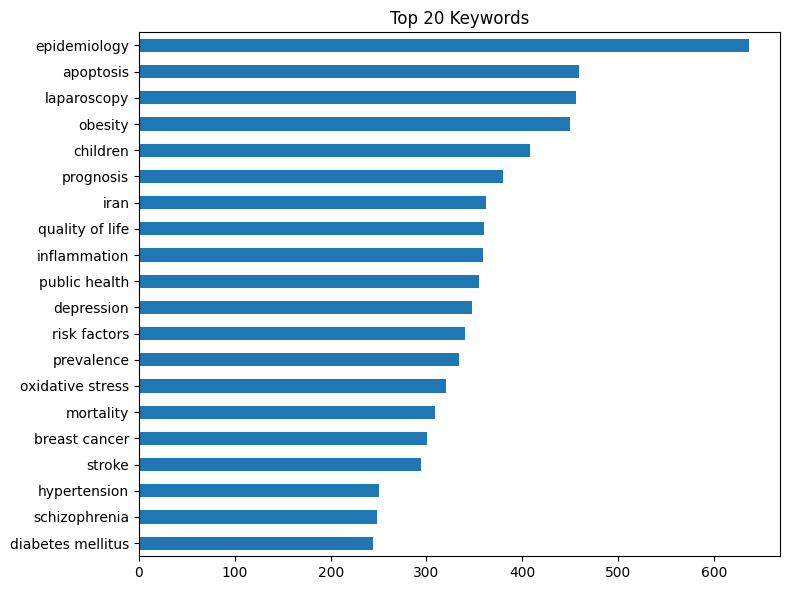

epidemiology         637
apoptosis            459
laparoscopy          456
obesity              450
children             408
prognosis            380
iran                 362
quality of life      360
inflammation         359
public health        355
depression           347
risk factors         340
prevalence           334
oxidative stress     320
mortality            309
breast cancer        301
stroke               294
hypertension         250
schizophrenia        248
diabetes mellitus    244
dtype: int64


: 

: 

In [ ]:
# Top 20 keywords
all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
top20 = pd.Series(dict(Counter(all_kwds).most_common(20)))
top20.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 20 Keywords')
plt.tight_layout()
plt.show()
print(top20.sort_values(ascending=False))

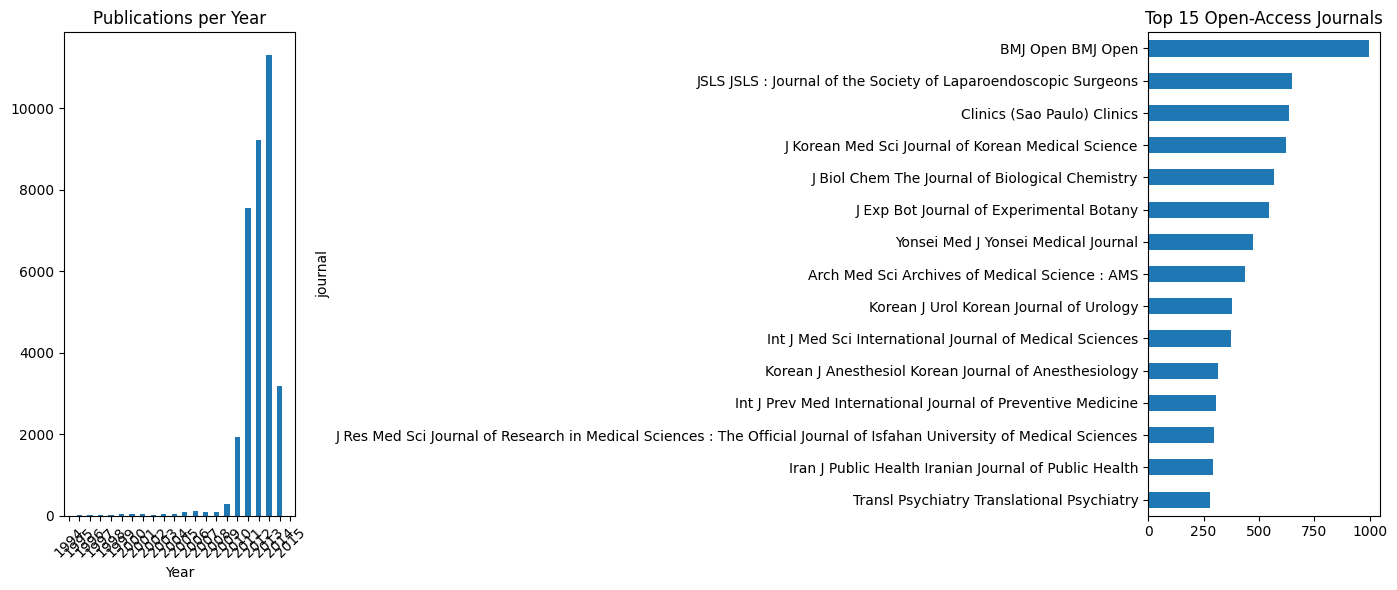

: 

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Publications per year
df['year'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Publications per Year')
axes[0].set_xlabel('Year')
axes[0].tick_params(axis='x', rotation=45)

# Top 15 journals
df['journal'].value_counts().head(15).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('Top 15 Open-Access Journals')

plt.tight_layout()
plt.show()

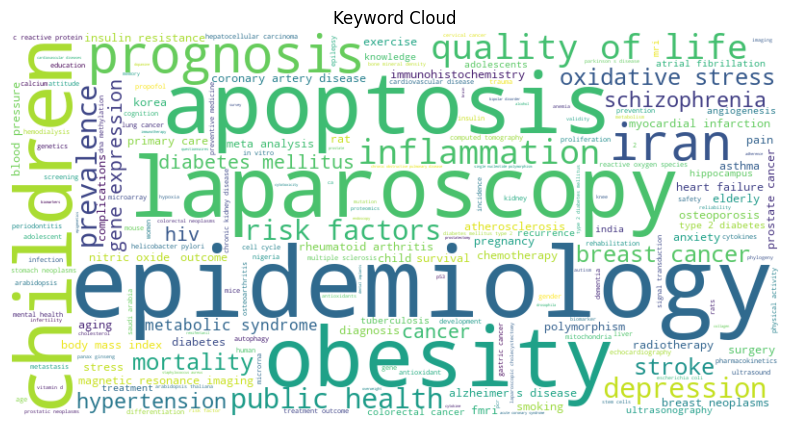

: 

: 

In [ ]:
from wordcloud import WordCloud
from collections import Counter

all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
freq = Counter(all_kwds)

wc = WordCloud(width=800, height=400, background_color='white')
wc.generate_from_frequencies(freq) 
plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Keyword Cloud')

plt.savefig("plots/wordcloud.png", dpi=150, bbox_inches='tight')
plt.show()

## 5 - Save Cleaned Pickle

Only run after reviewing EDA above.

In [ ]:
SAVE_CLEAN_PICKLE = True   # set True to save

if SAVE_CLEAN_PICKLE:
    PICKLE_OUT.parent.mkdir(parents=True, exist_ok=True)
    df.to_pickle(PICKLE_OUT)
    print(f"Saved: {PICKLE_OUT}  ({len(df)} articles)")
else:

    print("SAVE_CLEAN_PICKLE = False - nothing written.")

Saved: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\clean_articles.pkl  (34128 articles)


: 

: 

In [ ]:
#




: 

: 